# Playwright for Web Automation
### Modules 8 and 9: Playwright Fundamentals and Advanced Playwright

**What you'll be able to do by the end**

- Drive a real browser from Python: click, type, scroll, upload, download
- Find elements reliably with locators instead of fragile CSS paths
- Log in once and reuse the session
- Scrape dynamic pages (infinite scroll, JS-rendered content) into CSV
- Debug failing scripts with traces, screenshots, video and network logs
- Wrap it all in a script you could actually run on a schedule

**How to use this notebook:** run cells top to bottom. Every section ends with a small *Your turn* task. Do those. Reading alone won't stick.

> **Practice sites used here** (built for scraping practice, safe to hit):
> `quotes.toscrape.com`, `books.toscrape.com`, `the-internet.herokuapp.com`, and `playwright.dev`.
> Never point learning scripts at sites you don't own without checking their terms and `robots.txt`.

## About the detailed notes

Each section below ends with a **Detailed notes** cell. The lessons show you how to do something. The notes explain how it works, which options matter, what commonly goes wrong and how to choose between similar methods.

Suggested routine: run the section's code, read its notes, then do the *Your turn* task. Come back to the notes later as a reference. In VS Code, the Outline panel lists every notes heading.

Snippets in the notes are for reference and are not meant to be run as they stand. Names such as `loc`, `url` and `ctx` stand in for your own objects.

---
# PART 1: Playwright Fundamentals
---
## 1.1 Installing Playwright

Playwright is a browser automation library from Microsoft. One API drives Chromium, Firefox and WebKit.

Select a Python kernel, then run the setup cell below. It installs `playwright` and `pandas` in that kernel and downloads Chromium only if it is missing. The first run may take a few minutes.

```bash
pip install playwright
playwright install            # downloads the browsers (a few hundred MB)
playwright install chromium   # or just one
```

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

missing_packages = [name for name in ("playwright", "pandas") if importlib.util.find_spec(name) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

from playwright.async_api import async_playwright

async with async_playwright() as p:
    if not Path(p.chromium.executable_path).is_file():
        subprocess.check_call([sys.executable, "-m", "playwright", "install", "chromium"])

print("Playwright and Chromium are ready")

Playwright and Chromium are ready


### Sync vs async, and why it matters in Jupyter

Playwright has two Python APIs:

| API | Import | Use it for |
|---|---|---|
| Sync | `playwright.sync_api` | Plain `.py` scripts |
| Async | `playwright.async_api` | **Jupyter notebooks**, concurrent scraping |

Jupyter already runs an event loop, so the sync API crashes with *"Playwright Sync API inside the asyncio loop"*. In a notebook we use the **async API** and write `await` at the top level of cells. Everything you learn transfers: the sync version is the same code minus `async`/`await`.

### Detailed notes: 1.1 Installation, and sync vs async

**What gets installed**

| Piece | Installed by | Notes |
|---|---|---|
| Python package and driver | `pip install playwright` | Your code talks to a driver process, and the driver controls the browser |
| Browser builds | `playwright install` | Separate download, kept outside your project |

- On Windows, browsers are stored in `%USERPROFILE%\AppData\Local\ms-playwright`. On Linux it's `~/.cache/ms-playwright`, and on macOS it's `~/Library/Caches/ms-playwright`.
- Each Playwright release expects specific browser builds. **After upgrading the package, run `playwright install` again.**
- `python -m playwright install chromium` is the safest form inside a virtual environment, because it uses that environment's Python.
- On a fresh Linux server, `playwright install --with-deps chromium` also installs the system libraries.
- The error *"Executable doesn't exist"* means the browser hasn't been downloaded for this Playwright version.

**The `await` rule of thumb**

| Code | Needs `await`? | Why |
|---|---|---|
| `page.locator("div")`, `page.get_by_role("link")` | No | Only describes an element; nothing is sent to the browser |
| `page.url` | No | A property Playwright already holds |
| `await page.title()`, `await loc.click()` | Yes | Has to ask the browser |

A forgotten `await` often doesn't crash where you'd expect. Common signs are `RuntimeWarning: coroutine ... was never awaited`, or `<coroutine object ...>` showing up in printed output.

**Notebook vs script**

```python
# Plain .py file, sync API
from playwright.sync_api import sync_playwright

with sync_playwright() as p:
    browser = p.chromium.launch()
    page = browser.new_page()
    page.goto("https://quotes.toscrape.com")
    print(page.title())
    browser.close()
```

```python
# Plain .py file, async API: top-level await is not allowed, so use asyncio.run
import asyncio
from playwright.async_api import async_playwright

async def main():
    async with async_playwright() as p:
        browser = await p.chromium.launch()
        page = await browser.new_page()
        await page.goto("https://quotes.toscrape.com")
        print(await page.title())
        await browser.close()

asyncio.run(main())
```

**Notebook state:** variables such as `page` and `browser` live in the kernel until you restart it. If you run a cleanup cell and then re-run a cell above it, you'll see *"Target page, context or browser has been closed"*. Re-run the cell that started the session, or restart the kernel and run from the top.

## 1.2 Your first browser automation

The object chain you'll see everywhere:

```
Playwright  ->  Browser  ->  BrowserContext  ->  Page
(the engine)    (Chromium)   (an isolated profile)  (a tab)
```

In [2]:
from playwright.async_api import async_playwright

pw = await async_playwright().start()
browser = await pw.chromium.launch(headless=False, slow_mo=300)  # watch it work
page = await browser.new_page()

await page.goto("https://playwright.dev")
print("Title:", await page.title())
print("URL:  ", page.url)

Title: Fast and reliable end-to-end testing for modern web apps | Playwright
URL:   https://playwright.dev/


`headless=False` opens a visible window. `slow_mo=300` slows each action by 300 ms so you can follow along. Switch to `headless=True` for speed or servers.

**Your turn:** change `slow_mo` to `0` and compare how it feels.

In [3]:
# Always clean up when you're done with a browser session
await browser.close()
await pw.stop()

### A helper so we don't repeat boilerplate

We'll use this small helper for the rest of the notebook. It starts a browser, hands you a page, and you close it yourself at the end of a section.

In [4]:
from playwright.async_api import async_playwright

class Session:
    # Tiny wrapper: start browser, get a page, close everything cleanly.
    def __init__(self, headless=True, slow_mo=0, **context_args):
        self.headless, self.slow_mo, self.context_args = headless, slow_mo, context_args

    async def start(self):
        self.pw = await async_playwright().start()
        self.browser = await self.pw.chromium.launch(headless=self.headless, slow_mo=self.slow_mo)
        self.context = await self.browser.new_context(**self.context_args)
        self.page = await self.context.new_page()
        return self.page

    async def close(self):
        await self.context.close()
        await self.browser.close()
        await self.pw.stop()

s = Session(headless=True)
page = await s.start()
await page.goto("https://quotes.toscrape.com")
print(await page.title())

Quotes to Scrape


### Detailed notes: 1.2 Browser, context and page

| Object | What it is | Typical lifetime | Created with |
|---|---|---|---|
| `Playwright` | The driver connection | Whole program | `async_playwright().start()` |
| `Browser` | One running browser process | Whole job | `pw.chromium.launch()` |
| `BrowserContext` | An isolated profile with its own cookies and storage | One user, test or job | `browser.new_context()` |
| `Page` | One tab | One task | `context.new_page()` |

`browser.new_page()`, used in section 1.2, is a shortcut that also creates a private context for that page. It's fine for quick experiments. Create the context yourself when you need options, or more than one tab sharing a login.

**Launch options worth knowing**

```python
await pw.chromium.launch(
    headless=True,        # no visible window
    slow_mo=300,          # pause after each operation, in ms; for watching only
    channel="chrome",     # use the installed Chrome ("msedge" for Edge)
    timeout=60_000,       # how long to wait for the browser to start
)
```

The other engines work the same way: `pw.firefox.launch()` and `pw.webkit.launch()`. Install them first with `playwright install`.

**Closing things**

- Close in reverse order: context, browser, then `pw.stop()`.
- In scripts, prefer `async with async_playwright() as p:` because it stops the driver even if an error occurs. Close the context and browser in a `finally` block.
- In a notebook, an error in the middle of a section leaves the browser running. Run the section's close cell, or restart the kernel.

**How the `Session` helper works:** extra keyword arguments are collected in `**context_args` and passed to `new_context()`. So `Session(locale="en-IN", viewport={"width": 390, "height": 844})` works without any change to the class.

## 1.3 Navigation

`goto` is the main one. Also useful: `go_back`, `go_forward`, `reload`.

In [5]:
await page.goto("https://quotes.toscrape.com/page/2/")
print("on:", page.url)

await page.go_back()
print("back to:", page.url)

await page.go_forward()
print("forward to:", page.url)

await page.reload()
print("reloaded:", await page.title())

on: https://quotes.toscrape.com/page/2/
back to: https://quotes.toscrape.com/
forward to: https://quotes.toscrape.com/page/2/


reloaded: Quotes to Scrape


`goto` waits for the `load` event by default. You can change that:

```python
await page.goto(url, wait_until="domcontentloaded")  # faster, HTML parsed
await page.goto(url, wait_until="networkidle")       # no requests for 500ms (slow, avoid by default)
await page.goto(url, timeout=60_000)                 # ms
```

### Detailed notes: 1.3 Navigation

**`wait_until` values, fastest to slowest**

| Value | `goto` returns when | Use it for |
|---|---|---|
| `"commit"` | The response has started arriving and the page has begun to change | Rare; when you'll wait for something specific next |
| `"domcontentloaded"` | The HTML is parsed | Scraping, especially with images blocked |
| `"load"` (default) | The page and its resources have loaded | General use |
| `"networkidle"` | No network activity for 500 ms | Avoid; pages with ads or polling can take a long time or never settle |

**A bad status doesn't raise an error**

`goto` only raises when the navigation itself fails, such as a DNS failure or a timeout. A 404 or 500 is still a successful navigation, so check the status when it matters:

```python
response = await page.goto(url)
if response is None or not response.ok:
    raise RuntimeError(f"Bad response for {url}")
```

`response` can be `None`, for example when navigating to the same URL with a different `#hash`.

**Other details**

- The default navigation timeout is 30 seconds. Override it per call with `timeout=` or per context with `set_default_navigation_timeout()`.
- `go_back()` and `go_forward()` return `None` if there's no page to go to, so they don't raise an error.
- `page.url` is a property, while `await page.title()` is a method call. It's an easy pair to mix up.
- Set `base_url` on the context to use short paths:

```python
ctx = await browser.new_context(base_url="https://quotes.toscrape.com")
page = await ctx.new_page()
await page.goto("/login")
```

## 1.4 Locators and selectors

This is the most important skill in the whole course. A **locator** describes how to find an element. It is *lazy* and *auto-retrying*: nothing is looked up until you act on it, and Playwright keeps retrying until the element is ready.

### Preferred order (most stable first)

1. `get_by_role`: how a user or screen reader sees it (button, link, heading)
2. `get_by_label`: form fields by their label
3. `get_by_placeholder`, `get_by_text`
4. `get_by_test_id`: if devs added `data-testid`
5. `locator("css")` or `locator("xpath=...")`: last resort

In [6]:
await page.goto("https://quotes.toscrape.com")

# By role: the best habit
login_link = page.get_by_role("link", name="Login")
print("Login link count:", await login_link.count())

# By text
first_quote = page.get_by_text("The world as we have created it").first
print(await first_quote.text_content())

# By CSS
quotes = page.locator("div.quote")
print("Quotes on page:", await quotes.count())

Login link count: 1
“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
Quotes on page: 10


### Reading from elements

```python
await loc.text_content()     # raw text
await loc.inner_text()       # visible text, as rendered
await loc.get_attribute("href")
await loc.inner_html()
await loc.is_visible()
await loc.all()              # list of locators, one per match
await loc.all_inner_texts()  # list of strings
```

In [7]:
texts = await page.locator("span.text").all_inner_texts()
authors = await page.locator("small.author").all_inner_texts()

for t, a in list(zip(texts, authors))[:3]:
    print(f"{a}: {t[:60]}...")

Albert Einstein: “The world as we have created it is a process of our thinkin...
J.K. Rowling: “It is our choices, Harry, that show what we truly are, far ...
Albert Einstein: “There are only two ways to live your life. One is as though...


### Narrowing, chaining and filtering

Locators chain. Scope inside a parent so you never grab the wrong element on repeated layouts.

In [8]:
# Find the quote card by Einstein, then dig inside it
card = page.locator("div.quote").filter(has_text="Albert Einstein").first
print(await card.locator("span.text").inner_text())

tags = await card.locator("a.tag").all_inner_texts()
print("Tags:", tags)

# nth item (0-based), first, last
print(await page.locator("div.quote").nth(2).locator("small.author").inner_text())

“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
Tags: ['change', 'deep-thoughts', 'thinking', 'world']
Albert Einstein


### CSS and XPath quick reference

| Goal | CSS | XPath |
|---|---|---|
| By id | `#login` | `//*[@id='login']` |
| By class | `.quote` | `//*[contains(@class,'quote')]` |
| Attribute | `a[href*='tag']` | `//a[contains(@href,'tag')]` |
| Child | `div.quote > span` | `//div[@class='quote']/span` |
| Contains text | `:has-text("Love")` | `//*[contains(text(),'Love')]` |

**Your turn:** print the author of the *last* quote on the page and the `href` of the "Next" button.

### Detailed notes: 1.4 Locators and selectors

**Three properties explain most locator behaviour**

1. **Lazy:** creating a locator does nothing. The search runs when you use it.
2. **Fresh:** each action searches the page again, so a locator stays valid after the page updates.
3. **Strict:** an action on a single element fails if the locator matches more than one. This is the *strict mode violation* error, and it protects you from clicking the wrong thing.

**Which method for which job**

| Method | Finds | Example |
|---|---|---|
| `get_by_role` | Elements by accessibility role and name | `get_by_role("button", name="Save")` |
| `get_by_label` | Form fields by their label | `get_by_label("Email")` |
| `get_by_placeholder` | Inputs by placeholder | `get_by_placeholder("Search")` |
| `get_by_text` | Elements by visible text | `get_by_text("Welcome")` |
| `get_by_alt_text` | Images by alt text | `get_by_alt_text("Logo")` |
| `get_by_title` | Elements by title attribute | `get_by_title("Close")` |
| `get_by_test_id` | Elements by `data-testid` | `get_by_test_id("checkout")` |
| `locator` | CSS or XPath | `locator("article.product_pod")` |

Common roles: `button`, `link`, `heading`, `textbox`, `checkbox`, `radio`, `combobox`, `option`, `listitem`, `row`, `cell`. Headings can also be filtered by level: `get_by_role("heading", level=2)`.

**Matching is loose by default**

Name and text matching is case-insensitive and matches part of the string. Use `exact=True` for a case-sensitive, whole-string match, or a regular expression for a pattern.

```python
import re

page.get_by_role("link", name="next")              # also matches a book titled "The Next Thing"
page.get_by_role("link", name="next", exact=True)  # only a link named exactly "next"
page.get_by_role("link", name=re.compile(r"^next$", re.I))
```

This caused a real bug in this notebook. On `books.toscrape.com`, `name="next"` matches 3 links on page 24 and 2 on page 31, because book titles contain the word. Clicking it there raises a strict mode violation. Section 2.6 now uses `exact=True`.

**Which methods wait, and which don't**

| Waits for the element | Answers immediately |
|---|---|
| `click`, `fill`, `check`, `hover` | `count()` |
| `text_content`, `inner_text`, `inner_html` | `all()` |
| `get_attribute`, `input_value` | `all_inner_texts()`, `all_text_contents()` |
| `expect(loc).to_...` assertions | `is_visible()`, `is_hidden()` |

The right-hand column reads the page as it is right now. On a page still loading, `all_inner_texts()` can return `[]` and `count()` can return `0` with no error. Wait for the first item before reading a list:

```python
items = page.locator("div.quote")
await items.first.wait_for()
texts = await items.all_inner_texts()
```

**`text_content` vs `inner_text`**

| | `text_content()` | `inner_text()` |
|---|---|---|
| Hidden text | Included | Excluded |
| Whitespace | Kept as in the HTML | As displayed |
| Best for | Raw data | Text a user can see |

**Narrowing**

```python
card = page.locator("div.quote").filter(has_text="Einstein")            # contains this text
card = page.locator("div.quote").filter(has_not_text="Einstein")        # doesn't contain it
card = page.locator("div.quote").filter(has=page.locator("a.tag"))      # contains this element
visible = page.locator("button").filter(visible=True)                   # visible matches only

page.locator("div.quote").first
page.locator("div.quote").last
page.locator("div.quote").nth(2)                                        # 0-based

either = page.get_by_role("button", name="OK").or_(page.get_by_role("button", name="Yes"))
both = page.get_by_role("button").and_(page.get_by_title("Subscribe"))
```

`.first` silences the strict mode check, so use it only when "the first one" is what you actually mean.

**Choosing a stable selector**

- Good: roles, labels, test IDs and meaningful classes such as `article.product_pod`.
- Fragile: long paths such as `div > div:nth-child(3) > span`, and auto-generated classes such as `css-1x2y3z`.
- CSS and role locators reach inside open shadow DOM, but XPath doesn't. Closed shadow roots aren't supported.

## 1.5 Interacting with the page

Playwright actions **auto-wait**: before a click it checks the element is attached, visible, stable, enabled and not covered. You rarely need manual sleeps.

In [9]:
await page.goto("https://quotes.toscrape.com")

# Click a link, then confirm where we landed
await page.get_by_role("link", name="Login").click()
print("Now at:", page.url)

# Hover, double click, right click, keyboard
await page.get_by_role("button", name="Login").hover()
await page.keyboard.press("Tab")

Now at: https://quotes.toscrape.com/login


### Detailed notes: 1.5 Interacting with the page

**What each action waits for**

| Action | Visible | Stable | Receives events | Enabled | Editable |
|---|---|---|---|---|---|
| `click`, `dblclick`, `check`, `uncheck` | Yes | Yes | Yes | Yes | |
| `hover` | Yes | Yes | Yes | | |
| `fill`, `clear` | Yes | | | Yes | Yes |
| `select_option` | Yes | | | Yes | |
| `press`, `press_sequentially`, `focus`, `set_input_files` | | | | | |

- **Stable** means the element has stopped moving, such as at the end of an animation.
- **Receives events** means nothing else, such as a cookie banner, is covering it.
- If a check doesn't pass within the timeout (30 seconds by default), the action raises a timeout error that describes what it was waiting for.

**Click variations**

```python
await loc.click()
await loc.dblclick()
await loc.click(button="right")           # right click
await loc.click(modifiers=["Control"])    # Ctrl+click
await loc.click(position={"x": 5, "y": 5})
await loc.click(timeout=3000)
await loc.click(trial=True)               # run the checks without clicking
await loc.click(force=True)               # skip the checks
```

Use `force=True` sparingly. It can click something a real user couldn't, so a script can pass while the page is actually broken.

**Keyboard and mouse**

```python
await loc.press("Enter")                       # focus the element, then press
await page.keyboard.press("Control+A")         # goes to whatever has focus
await page.keyboard.type("hello")
await page.mouse.wheel(0, 2000)                # scroll down 2000 px
await loc.scroll_into_view_if_needed()
await page.locator("#item").drag_to(page.locator("#target"))
```

Prefer locator methods to raw mouse coordinates. They survive layout changes and include the waiting described above.

## 1.6 Forms

| Action | Method |
|---|---|
| Type text (sets value) | `fill()` |
| Type key by key (fires key events) | `press_sequentially()` |
| Dropdown | `select_option()` |
| Checkbox / radio | `check()`, `uncheck()`, `set_checked()` |
| File upload | `set_input_files()` |
| Press a key | `press("Enter")` |

`fill()` is faster and what you want 95% of the time. Use `press_sequentially()` when a site reacts to every keystroke (autocomplete).

In [10]:
await page.goto("https://quotes.toscrape.com/login")

await page.locator("#username").fill("student")
await page.locator("#password").fill("anything-works-here")
await page.get_by_role("button", name="Login").click()

# After login the link text flips to Logout
print("Logged in?", await page.get_by_role("link", name="Logout").is_visible())

Logged in? True


In [11]:
# Dropdowns, checkboxes and inputs on a page made for this
await page.goto("https://the-internet.herokuapp.com/dropdown")
await page.locator("#dropdown").select_option("2")           # by value
print("Selected:", await page.locator("#dropdown").input_value())

await page.goto("https://the-internet.herokuapp.com/checkboxes")
boxes = page.locator("input[type=checkbox]")
await boxes.nth(0).check()
await boxes.nth(1).uncheck()
print("box1:", await boxes.nth(0).is_checked(), "| box2:", await boxes.nth(1).is_checked())

Selected: 2


box1: True | box2: False


In [12]:
# File upload: create a tiny file, then upload it
from pathlib import Path
Path("demo_upload.txt").write_text("hello from playwright")

await page.goto("https://the-internet.herokuapp.com/upload")
await page.locator("#file-upload").set_input_files("demo_upload.txt")
await page.locator("#file-submit").click()
print(await page.locator("#uploaded-files").inner_text())

demo_upload.txt


**Your turn:** on `https://the-internet.herokuapp.com/login` the credentials are shown on the page (`tomsmith` / `SuperSecretPassword!`). Log in and print the green success banner text.

### Detailed notes: 1.6 Forms

**Text fields**

| Need | Use |
|---|---|
| Set a value | `fill("text")`; it replaces what's already there |
| Empty a field | `clear()` |
| Fire key events, as autocomplete needs | `press_sequentially("text", delay=100)` |
| Read the current value | `input_value()`; `text_content()` doesn't return what's typed into an input |

**Dropdowns**

```python
await loc.select_option("2")                # by value
await loc.select_option(label="Option 2")   # by visible text
await loc.select_option(index=1)            # by position
await loc.select_option(["a", "b"])         # multi-select
```

`select_option` only works on a real `<select>` element. Many modern dropdowns are built from ordinary elements, so click them open and then click the choice:

```python
await page.get_by_role("combobox", name="Country").click()
await page.get_by_role("option", name="India").click()
```

**Checkboxes and radio buttons**

- `check()` is safe to repeat. If the box is already ticked, nothing changes, whereas `click()` would untick it.
- `set_checked(True)` or `set_checked(False)` is handy when the value comes from a variable.
- Read state with `is_checked()`. Also useful: `is_enabled()`, `is_disabled()`, `is_editable()`.

**File uploads**

```python
await loc.set_input_files("report.pdf")
await loc.set_input_files(["a.png", "b.png"])    # several files
await loc.set_input_files([])                    # clear the selection
await loc.set_input_files({                      # from memory, no file on disk
    "name": "note.txt", "mimeType": "text/plain", "buffer": b"hello",
})

# When a button opens the file picker and there's no input to target
async with page.expect_file_chooser() as fc_info:
    await page.get_by_role("button", name="Upload").click()
chooser = await fc_info.value
await chooser.set_files("report.pdf")
```

`set_input_files` also works on hidden inputs, which many styled upload buttons use.

**Good habits**

- Prefer `get_by_label` for fields when the page has proper labels. This notebook uses `#username` because IDs are the simplest option on that page.
- After submitting, confirm the result by checking for a success message or a new URL. A click that didn't raise an error doesn't prove the form was accepted.
- Read real credentials from environment variables, never from notebook cells. Notebooks are easy to share by accident, and saved outputs travel with them.

## 1.7 Screenshots

```python
await page.screenshot(path="x.png")                     # viewport
await page.screenshot(path="x.png", full_page=True)     # whole scrollable page
await locator.screenshot(path="x.png")                  # one element
```

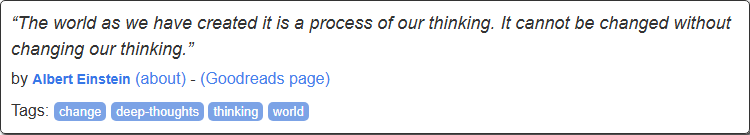

In [13]:
await page.goto("https://quotes.toscrape.com")

await page.screenshot(path="shot_viewport.png")
await page.screenshot(path="shot_full.png", full_page=True)
await page.locator("div.quote").first.screenshot(path="shot_quote.png")

from IPython.display import Image
Image("shot_quote.png")

Screenshots are your first debugging tool and a great way to build visual regression checks. You can also mask dynamic regions: `page.screenshot(mask=[page.locator(".ad")])`.

## 1.8 PDF generation

`page.pdf()` prints the page like Chrome's *Save as PDF*. **Chromium headless only.**

In [14]:
await page.goto("https://books.toscrape.com")
await page.pdf(path="books_home.pdf", format="A4", print_background=True,
               margin={"top": "1cm", "bottom": "1cm"})
print("Saved books_home.pdf")

Saved books_home.pdf


A useful pattern: render your own HTML (invoice, report) straight to PDF with `page.set_content(html)` then `page.pdf()`.

In [15]:
html = '''
<html><body style="font-family:Arial;padding:40px">
  <h1>Invoice #1042</h1>
  <p>Client: Demo Traders</p>
  <table border="1" cellpadding="8" style="border-collapse:collapse">
    <tr><th>Item</th><th>Amount</th></tr>
    <tr><td>Meta Ads setup</td><td>15,000</td></tr>
    <tr><td>Reporting</td><td>5,000</td></tr>
  </table>
  <h3>Total: 20,000</h3>
</body></html>
'''
await page.set_content(html)
await page.pdf(path="invoice.pdf", format="A4")
print("invoice.pdf created")

invoice.pdf created


### Detailed notes: 1.7 Screenshots and 1.8 PDFs

**Screenshot options**

```python
await page.screenshot(
    path="x.png",
    full_page=True,                     # the whole scrollable page
    clip={"x": 0, "y": 0, "width": 800, "height": 400},  # a fixed area of the page
    mask=[page.locator(".ad")],         # cover dynamic areas
    animations="disabled",              # finish or cancel CSS animations first
    type="jpeg", quality=70,            # smaller files
    omit_background=True,               # transparent background (PNG only)
)

png_bytes = await page.screenshot()     # no path: returns bytes, nothing written to disk
```

- `clip` can't be combined with an element screenshot, because `locator.screenshot()` already crops to the element.
- Pages that load images as you scroll may show blank areas in a `full_page` screenshot. Scroll through the page first.
- An element screenshot uses the same waiting as other actions, so it can time out if the element never appears.

**PDF options**

```python
await page.emulate_media(media="screen")   # use on-screen styles instead of print styles
await page.pdf(
    path="report.pdf",
    format="A4",
    landscape=True,
    print_background=True,                 # off by default, so backgrounds are omitted
    margin={"top": "1cm", "bottom": "1cm", "left": "1cm", "right": "1cm"},
    page_ranges="1-3",
    display_header_footer=True,
    footer_template='<div style="font-size:9px;width:100%;text-align:center">'
                    'Page <span class="pageNumber"></span> of <span class="totalPages"></span></div>',
)
```

- `pdf()` works in Chromium only, and it's safest to run headless, as this notebook does.
- By default the PDF uses the page's *print* styles, which is why it can look different from the screen.
- Headers and footers need an explicit font size, because the default is very small.

**Generating reports from your own HTML**

`set_content` plus `pdf` gives you a PDF report generator with HTML and CSS as the layout language. The page starts at `about:blank`, so use absolute URLs for external images and stylesheets, or put your CSS inline. Always escape data that comes from outside with `html.escape()` before placing it in the template.

## 1.9 Downloads

Downloads are an *event*. Wrap the click that triggers it in `expect_download()`.

In [16]:
# Self-contained page with a download link, so this works anywhere
await page.set_content('''
  <a id="dl" download="hello.txt"
     href="data:text/plain;base64,SGVsbG8gZnJvbSBQbGF5d3JpZ2h0IQ==">Download file</a>
''')

async with page.expect_download() as dl_info:
    await page.locator("#dl").click()

download = await dl_info.value
print("Suggested name:", download.suggested_filename)
await download.save_as("downloaded_" + download.suggested_filename)
print(Path("downloaded_hello.txt").read_text())

Suggested name: hello.txt


Hello from Playwright!


**Real sites:** the same pattern works for "Export CSV" buttons. Create the context with `accept_downloads=True` if you ever see downloads silently ignored (it's the default in recent versions).

## 1.10 Handling dialogs and new tabs

Alerts, confirms and prompts are blocked until handled. Register a handler *before* the action.

In [ ]:
# Event handlers run outside this cell's output, so store the message and print it below
dialog_messages = []

async def handle_dialog(dialog):
    dialog_messages.append(dialog.message)
    await dialog.accept()

page.once("dialog", handle_dialog)

await page.goto("https://the-internet.herokuapp.com/javascript_alerts")
await page.get_by_role("button", name="Click for JS Alert").click()
print("Dialog said:", dialog_messages[0])
print(await page.locator("#result").inner_text())

In [18]:
# Links that open a new tab
await page.goto("https://the-internet.herokuapp.com/windows")
async with page.context.expect_page() as new_page_info:
    await page.get_by_role("link", name="Click Here").click()

new_tab = await new_page_info.value
await new_tab.wait_for_load_state()
print("New tab heading:", await new_tab.locator("h3").inner_text())
await new_tab.close()

New tab heading: New Window


In [19]:
await s.close()

### Detailed notes: 1.9 Downloads and 1.10 Dialogs and tabs

**Why these use `async with`**

Downloads, popups and similar events can fire as soon as the click happens. If you start waiting after the click, you may miss the event and wait until the timeout. The pattern starts listening first:

```python
async with page.expect_download() as info:   # 1. start listening
    await page.locator("#dl").click()        # 2. trigger it
download = await info.value                  # 3. get the result
```

**Download object**

| Member | Purpose |
|---|---|
| `download.suggested_filename` | Name the server or link proposes |
| `await download.save_as(path)` | Copy the file somewhere permanent |
| `await download.path()` | Temporary location, after it finishes |
| `await download.failure()` | Error message, or `None` if it succeeded |

Temporary download files are deleted when the context closes, so call `save_as` before closing.

**Dialogs**

| Situation | What happens |
|---|---|
| No handler registered | Playwright dismisses the dialog automatically (a confirm returns false) |
| Handler registered | **You must** call `accept()` or `dismiss()`, or the action that opened it stalls |

- `page.once` handles the next dialog only, while `page.on` handles all of them until `page.remove_listener` is called.
- Useful members: `dialog.type` (`alert`, `confirm`, `prompt`, `beforeunload`), `dialog.message`, `dialog.default_value`.
- For a prompt, pass the answer: `await dialog.accept("my answer")`.

**Printing inside event handlers**

In this notebook, `print()` inside a Playwright handler doesn't appear under the cell you're running. So the handlers store values in a list and the cell prints them. That's why the dialog cell here collects `dialog_messages`. In a plain `.py` script, printing directly from a handler works normally.

Handlers can be `async def` functions, as `handle_dialog` is. That's cleaner than a lambda that schedules a coroutine.

**New tabs and popups**

```python
# A popup opened by this page
async with page.expect_popup() as popup_info:
    await page.get_by_role("link", name="Click Here").click()
popup = await popup_info.value

# Any new page in the context, whoever opened it
async with page.context.expect_page() as page_info:
    await page.get_by_role("link", name="Click Here").click()
new_tab = await page_info.value

await new_tab.wait_for_load_state()
```

New tabs in the same context share cookies with the original, so they keep the login. `context.pages` lists every open tab, and `await page.bring_to_front()` activates one.

## Part 1 recap

- Async API in Jupyter, sync API in scripts
- `Playwright -> Browser -> Context -> Page`
- Prefer `get_by_role` / `get_by_label` over brittle CSS
- Actions auto-wait. No `time.sleep`
- `expect_download()` and `expect_page()` wrap the click that triggers them

### Mini project 1
Scrape **all 10 pages** of `quotes.toscrape.com` by clicking "Next" until it disappears. Save quote, author and tags to a list of dicts and print the total count (it should be 100).

---
# PART 2: Advanced Playwright and Web Automation
---

In [20]:
from playwright.async_api import async_playwright, expect, TimeoutError as PWTimeout
import asyncio, json, csv, time, logging
from pathlib import Path

## 2.1 Browser contexts

A **context** is an isolated browser profile: its own cookies, storage, cache and permissions. Creating one costs milliseconds, launching a browser costs seconds. So:

> **One browser, many contexts.** Use a fresh context per user, per test, or per scraping job.

Below we log in as "user A" in one context and show that "user B" in another context is still logged out.

In [21]:
pw = await async_playwright().start()
browser = await pw.chromium.launch(headless=True)

ctx_a = await browser.new_context()
ctx_b = await browser.new_context()
page_a = await ctx_a.new_page()
page_b = await ctx_b.new_page()

# Log A in
await page_a.goto("https://quotes.toscrape.com/login")
await page_a.locator("#username").fill("a")
await page_a.locator("#password").fill("a")
await page_a.get_by_role("button", name="Login").click()

await page_b.goto("https://quotes.toscrape.com")

print("A sees Logout:", await page_a.get_by_role("link", name="Logout").is_visible())
print("B sees Login: ", await page_b.get_by_role("link", name="Login").is_visible())

A sees Logout: True
B sees Login:  True


### Context options worth knowing

```python
await browser.new_context(
    viewport={"width": 390, "height": 844},   # phone size
    user_agent="...",
    locale="en-IN",
    timezone_id="Asia/Kolkata",
    geolocation={"latitude": 9.93, "longitude": 76.26},
    permissions=["geolocation"],
    color_scheme="dark",
    extra_http_headers={"X-Demo": "1"},
)
# Or emulate a real device:
iphone = pw.devices["iPhone 13"]
await browser.new_context(**iphone)
```

In [22]:
iphone = pw.devices["iPhone 13"]
ctx_m = await browser.new_context(**iphone)
pm = await ctx_m.new_page()
await pm.goto("https://playwright.dev")
await pm.screenshot(path="mobile.png")
print("viewport:", pm.viewport_size)
await ctx_m.close()

viewport: {'width': 390, 'height': 664}


### Detailed notes: 2.1 Browser contexts

**What a context isolates:** cookies, localStorage and sessionStorage, cache, permissions, and its emulation settings. Two contexts in one browser behave like two separate people on two separate computers.

**Which option should I use?**

| Goal | Option |
|---|---|
| Screen size | `viewport={"width": 1280, "height": 720}` |
| Language and region | `locale="en-IN"`, `timezone_id="Asia/Kolkata"` |
| Location | `geolocation={...}` with `permissions=["geolocation"]` |
| Dark mode | `color_scheme="dark"` |
| Short URLs | `base_url="https://example.com"` |
| Extra headers | `extra_http_headers={"X-Demo": "1"}` |
| Saved login | `storage_state="auth_state.json"` |
| Testing a site with a self-signed certificate | `ignore_https_errors=True` |
| Offline testing | `offline=True` |
| Recording | `record_video_dir="videos/"`, `record_har_path="net.har"` |

**Changing an existing context**

```python
await ctx.add_cookies([{"name": "lang", "value": "en", "url": "https://example.com"}])
print(await ctx.cookies())
await ctx.clear_cookies()
await ctx.set_extra_http_headers({"X-Demo": "1"})
await ctx.add_init_script("window.demoFlag = true")   # runs in every page before its own scripts
```

**Device emulation**

`pw.devices["iPhone 13"]` is a plain dictionary of context options, including `user_agent`, `viewport`, `device_scale_factor`, `is_mobile`, `has_touch` and `default_browser_type`.

- `viewport` is the visible browser area, not the physical screen. That's why the cell above prints a height of 664 for an iPhone 13.
- Emulation copies settings, not the actual phone or its browser. Test on a real device for anything critical.
- You can override one value: `new_context(**iphone, locale="en-IN")`.

**How to split work**

- New context: a different user, test or scraping job.
- New page in the same context: another tab for the same logged-in user.
- New browser: rarely needed, such as when comparing engines.

## 2.2 Authentication: log in once, reuse everywhere

Logging in on every run is slow, and noisy for the site. Playwright can save cookies and local storage to a file with `storage_state` and load it into new contexts.

In [23]:
# Save A's logged-in session
await ctx_a.storage_state(path="auth_state.json")
print("Saved. Cookies:", [c["name"] for c in json.loads(Path("auth_state.json").read_text())["cookies"]])

# Brand new context, already logged in
ctx_c = await browser.new_context(storage_state="auth_state.json")
page_c = await ctx_c.new_page()
await page_c.goto("https://quotes.toscrape.com")
print("Restored session:", await page_c.get_by_role("link", name="Logout").is_visible())

Saved. Cookies: ['session']


Restored session: True


**Production pattern:**

```python
STATE = Path("auth_state.json")

async def get_context(browser):
    if STATE.exists():
        ctx = await browser.new_context(storage_state=STATE)
        # check it's still valid, else fall through to a fresh login
        ...
    ...
    await ctx.storage_state(path=STATE)   # refresh after login
```

**Security:** `auth_state.json` is basically your password. Add it to `.gitignore`, never commit it, never share it. Read credentials from environment variables, not from source code.

### Other auth styles

- **HTTP basic auth:** `new_context(http_credentials={"username": "...", "password": "..."})`
- **Token / header based:** `extra_http_headers={"Authorization": "Bearer ..."}`
- **2FA / CAPTCHA:** log in manually once with `headless=False`, then save `storage_state`. Don't try to bypass CAPTCHAs.

In [24]:
# Basic auth demo: this site returns 200 only with admin/admin
ctx_basic = await browser.new_context(http_credentials={"username": "admin", "password": "admin"})
pb = await ctx_basic.new_page()
await pb.goto("https://the-internet.herokuapp.com/basic_auth")
print(await pb.locator("p").first.inner_text())
await ctx_basic.close()

Congratulations! You must have the proper credentials.


### Detailed notes: 2.2 Authentication

**What `storage_state` saves**

| Saved | Not saved |
|---|---|
| Cookies | sessionStorage |
| localStorage | The current page and any open tabs |
| IndexedDB, only with `storage_state(indexed_db=True)` | |

If a site keeps its login in sessionStorage, restoring the file won't log you in.

**A complete flow**

```python
import os
from pathlib import Path

STATE = Path("auth_state.json")

async def is_logged_in(page):
    await page.goto("https://quotes.toscrape.com")
    return await page.get_by_role("link", name="Logout").is_visible()

async def login(page):
    await page.goto("https://quotes.toscrape.com/login")
    await page.locator("#username").fill(os.environ["APP_USER"])
    await page.locator("#password").fill(os.environ["APP_PASSWORD"])
    await page.get_by_role("button", name="Login").click()
    await page.get_by_role("link", name="Logout").wait_for()

async def get_context(browser):
    if STATE.exists():
        ctx = await browser.new_context(storage_state=STATE)
        page = await ctx.new_page()
        if await is_logged_in(page):
            return ctx
        await ctx.close()                      # the saved session has expired

    ctx = await browser.new_context()
    await login(await ctx.new_page())
    await ctx.storage_state(path=STATE)
    return ctx
```

**Choosing a method**

| Site uses | Approach |
|---|---|
| Normal login form | Log in once, save `storage_state` |
| Browser password popup | `http_credentials={...}` |
| API token | `extra_http_headers={"Authorization": "Bearer ..."}` |
| 2FA, CAPTCHA or SSO | Log in by hand once, then save the state |

The manual option has a ready-made command, which saves the state when you close the window:

```bash
playwright codegen --save-storage=auth_state.json https://example.com/login
playwright codegen --load-storage=auth_state.json https://example.com
```

**Common problems**

- Sessions expire, so always have a way to log in again, as `get_context` does above.
- Some sites tie a session to an IP address or browser, so a saved file may not work on another machine.
- Two jobs sharing one saved session can log each other out if the site allows only one session.

**Security checklist**

- Treat `auth_state.json` like a password: anyone holding it can act as that user until the session ends.
- Add it to `.gitignore`, and keep it out of synced or shared folders where possible.
- Trace files can also contain cookies and typed passwords, so handle them the same way.
- Use a separate low-privilege account for automation when you can.

## 2.3 Waiting strategies

This is where most flaky scripts come from. The hierarchy:

1. **Do nothing.** Actions and `expect()` assertions already auto-wait.
2. **Wait for a specific thing:** an element, a URL, a response.
3. **Wait for a condition:** `wait_for_function`.
4. **Never:** `time.sleep()` / `wait_for_timeout()` (OK for quick debugging only).

In [25]:
page = page_a
await page.goto("https://the-internet.herokuapp.com/dynamic_loading/1")

await page.get_by_role("button", name="Start").click()

# Element is in the DOM but hidden, then appears after ~5s.
# wait_for waits for the state you ask for:
await page.locator("#finish").wait_for(state="visible", timeout=15_000)
print(await page.locator("#finish").inner_text())

Hello World!


In [26]:
# Web-first assertions: retry until true or timeout. Best for checks.
await page.goto("https://the-internet.herokuapp.com/dynamic_loading/2")
await page.get_by_role("button", name="Start").click()

await expect(page.locator("#finish h4")).to_have_text("Hello World!", timeout=15_000)
print("assertion passed")

assertion passed


In [27]:
# Other useful waits
await page.goto("https://quotes.toscrape.com")

# Wait for a URL after a click
await page.get_by_role("link", name="Next").click()
await page.wait_for_url("**/page/2/")

# Wait for a network response triggered by an action
async with page.expect_response(lambda r: "/page/3/" in r.url and r.status == 200) as resp_info:
    await page.get_by_role("link", name="Next").click()
resp = await resp_info.value
print("Got response:", resp.url, resp.status)

# Wait for any JS condition
await page.wait_for_function("document.querySelectorAll('.quote').length >= 10")

# Wait for load state
await page.wait_for_load_state("domcontentloaded")

Got response: https://quotes.toscrape.com/page/3/ 200


### Handling timeouts like an adult

```python
try:
    await page.locator("#maybe-popup").click(timeout=3000)
except PWTimeout:
    pass   # popup didn't show, carry on
```

You can also set defaults for the whole context: `ctx.set_default_timeout(15_000)` and `ctx.set_default_navigation_timeout(45_000)`.

**Your turn:** `https://the-internet.herokuapp.com/dynamic_controls`. Click *Remove*, wait for "It's gone!", then click *Enable* and type into the input once it's enabled. No sleeps allowed.

### Detailed notes: 2.3 Waiting strategies

**Pick the wait by what you're waiting for**

| Waiting for | Use |
|---|---|
| To act on an element | Nothing: the action waits |
| To check a value | `await expect(loc).to_have_text(...)` |
| An element to appear or disappear | `await loc.wait_for(state=...)` |
| A new URL | `await page.wait_for_url(...)` |
| A network call triggered by an action | `async with page.expect_response(...)` |
| A condition only JavaScript can check | `await page.wait_for_function(...)` |
| A new page to finish loading | `await page.wait_for_load_state(...)` |

**`wait_for` states**

| State | Waits until the element is |
|---|---|
| `"visible"` (default) | In the page and has a visible box |
| `"hidden"` | Missing or not visible |
| `"attached"` | In the page, visible or not |
| `"detached"` | Gone from the page |

**Common `expect` assertions**

```python
await expect(loc).to_be_visible()
await expect(loc).to_be_hidden()
await expect(loc).to_be_enabled()
await expect(loc).to_be_checked()
await expect(loc).to_have_text("Exact text")
await expect(loc).to_contain_text("part of it")
await expect(loc).to_have_value("typed value")
await expect(loc).to_have_attribute("href", "/next")
await expect(loc).to_have_count(10)
await expect(page).to_have_url("https://example.com/done")
await expect(page).to_have_title("Dashboard")
await expect(loc).not_to_be_visible()        # negative form
```

**Why `expect` beats `assert`**

```python
assert await loc.is_visible()       # checks once; fails if the page is a moment late
await expect(loc).to_be_visible()   # retries until true or the timeout
```

**Timeouts**

| Kind | Default | Change it with |
|---|---|---|
| Actions and locator waits | 30 s | `timeout=` or `ctx.set_default_timeout()` |
| Navigation | 30 s | `timeout=` or `ctx.set_default_navigation_timeout()` |
| `expect` assertions | 5 s | `timeout=` or `expect.set_options(timeout=...)` |

Notice that `expect` has a much shorter default. That's why the dynamic loading cell passes `timeout=15_000`.

**Listen before you act**

```python
# Wrong: the response may arrive before you start waiting
await button.click()
response = await page.wait_for_event("response")

# Right: listening starts first
async with page.expect_response("**/api/items*") as info:
    await button.click()
response = await info.value
```

**Catching timeouts**

Playwright's `TimeoutError` is a different class from Python's built-in one, so a plain `except TimeoutError` won't catch it. This notebook imports it as `PWTimeout` to make that clear. Only catch it when the wait is truly optional, like a popup that may not appear. Otherwise you hide real failures.

**When a fixed wait is acceptable**

`wait_for_timeout()` is acceptable for slowing down politely or when no signal exists, as in the scroll loop in section 2.4. If you add one to make a script stop failing, there's probably a real signal you should wait for instead.

## 2.4 Dynamic websites: infinite scroll and JS-rendered content

Two common cases:

1. **Content rendered by JavaScript.** `requests` + BeautifulSoup sees an empty shell. Playwright sees the final DOM.
2. **Infinite scroll.** New items load as you scroll.

`quotes.toscrape.com/js/` renders quotes with JavaScript. `/scroll` is an infinite scroll page.

In [28]:
page = await ctx_c.new_page()

await page.goto("https://quotes.toscrape.com/scroll")

async def scroll_to_end(page, item_selector, pause=800, max_rounds=30):
    # Scroll until the item count stops growing.
    last = 0
    for round_ in range(max_rounds):
        await page.mouse.wheel(0, 4000)
        await page.wait_for_timeout(pause)       # fine here: no better signal exists
        count = await page.locator(item_selector).count()
        print(f"round {round_+1}: {count} items")
        if count == last:
            break
        last = count
    return last

total = await scroll_to_end(page, "div.quote")
print("Total quotes loaded:", total)

round 1: 20 items


round 2: 30 items


round 3: 40 items


round 4: 50 items


round 5: 60 items


round 6: 70 items


round 7: 80 items


round 8: 90 items


round 9: 100 items


round 10: 100 items
Total quotes loaded: 100


### Peek at the network: often there's an API

Before scraping the DOM, check if the page loads its data from a JSON endpoint. That is faster and cleaner. Playwright lets you listen to every response.

In [29]:
api_hits = []

def on_response(resp):
    if "application/json" in resp.headers.get("content-type", ""):
        api_hits.append(resp.url)

page.on("response", on_response)
await page.goto("https://quotes.toscrape.com/scroll")
await page.mouse.wheel(0, 5000)
await page.wait_for_timeout(1500)
print("JSON calls seen:", api_hits[:5])

JSON calls seen: ['https://quotes.toscrape.com/api/quotes?page=1', 'https://quotes.toscrape.com/api/quotes?page=2']


### Detailed notes: 2.4 Dynamic websites

**First, check what kind of page it is**

1. Right-click and choose **View Page Source**. This is the raw HTML before JavaScript runs.
2. If your data is there, the page may not need a browser at all. `requests` and BeautifulSoup are lighter.
3. If it's missing, open DevTools, go to the **Network** tab and filter by **Fetch/XHR** while you use the page.
4. If a JSON request contains the data, calling it directly is usually the fastest and cleanest option. Otherwise, use Playwright's rendered page.

**Using the JSON endpoint**

The network cell above found `https://quotes.toscrape.com/api/quotes?page=1`. Instead of scrolling, you can call it with `ctx.request`, which shares the context's cookies:

```python
response = await ctx.request.get("https://quotes.toscrape.com/api/quotes?page=1")
data = await response.json()
print(data.keys())
```

Always check `response.ok`, and read the site's terms before relying on an undocumented endpoint, since it can change without notice.

**Pagination patterns**

| Pattern | How to recognise it | Approach |
|---|---|---|
| Numbered pages | URL changes, such as `/page/2/` | Loop over the URLs, or click Next until it's gone |
| Load more button | A button adds items | Click until the button disappears |
| Infinite scroll | Scrolling adds items | Scroll until the count stops growing |
| Virtual list | The item count stays low as you scroll | Collect items as you scroll, and remove duplicates |

**A better scroll loop**

The lesson's loop always waits a fixed time. This version continues as soon as new items arrive and stops when none arrive in time:

```python
async def scroll_until_done(page, selector, timeout=5000, max_rounds=100):
    items = page.locator(selector)
    await items.first.wait_for()
    for _ in range(max_rounds):
        before = await items.count()
        await items.last.scroll_into_view_if_needed()
        await page.mouse.wheel(0, 4000)
        try:
            await page.wait_for_function(
                "([sel, n]) => document.querySelectorAll(sel).length > n",
                arg=[selector, before],
                timeout=timeout,
            )
        except PWTimeout:
            break                # nothing new arrived, so this is the end
    return await items.count()
```

Always keep a `max_rounds` limit, because some feeds never end.

**Listening to responses**

- The handler sees every response in the page, so filter by URL or content type.
- Handlers can be async. For example, `async def on_response(resp): data = await resp.json()`.
- Reading a body can fail if the page has already navigated away, so wrap it in `try/except` in long-running jobs.
- Remove a handler you no longer need: `page.remove_listener("response", on_response)`.

**If the scroll doesn't work**

`mouse.wheel` scrolls whatever is under the mouse. If the list scrolls inside its own panel, move the mouse there first, or scroll the panel directly:

```python
await page.locator("#panel").evaluate("el => el.scrollTo(0, el.scrollHeight)")
```

## 2.5 Network control: block, mock and modify

`page.route()` intercepts requests. Three uses:

- **Block** images, fonts and trackers so scraping is faster
- **Mock** an API response to test your code
- **Modify** headers

In [30]:
ctx_fast = await browser.new_context()

# Block heavy stuff
async def block_assets(route):
    if route.request.resource_type in {"image", "font", "media"}:
        await route.abort()
    else:
        await route.continue_()

await ctx_fast.route("**/*", block_assets)

pf = await ctx_fast.new_page()
t0 = time.time()
await pf.goto("https://books.toscrape.com")
print(f"Loaded without images in {time.time()-t0:.2f}s,",
      await pf.locator("article.product_pod").count(), "books")
await ctx_fast.close()

Loaded without images in 2.75s, 20 books


In [31]:
# Mock a response
ctx_mock = await browser.new_context()
pmock = await ctx_mock.new_page()

await pmock.route("**/api/prices", lambda route: route.fulfill(
    status=200, content_type="application/json",
    body=json.dumps({"price": 999, "currency": "INR"})
))

await pmock.set_content("<h1 id='p'>loading...</h1>")
# fetch needs a real origin, so navigate to a blank page on a host first
await pmock.goto("https://example.com")
result = await pmock.evaluate("fetch('/api/prices').then(r => r.json())")
print("Mocked API returned:", result)
await ctx_mock.close()

Mocked API returned: {'price': 999, 'currency': 'INR'}


### Detailed notes: 2.5 Network control

**The handler's choices**

| Call | Effect | Typical use |
|---|---|---|
| `await route.continue_()` | Sends the request on | Default path; can change `headers=`, `url=`, `method=`, `post_data=` |
| `await route.abort()` | Blocks it | Images, trackers |
| `await route.fulfill(...)` | Answers without the server | Mocks and tests |
| `await route.fetch()` | Gets the real response so you can edit it | Changing part of a real reply |
| `await route.fallback()` | Passes to the next matching handler | Layered handlers |

**Mocking**

```python
await page.route("**/api/items", lambda route: route.fulfill(json={"items": []}))
await page.route("**/logo.png", lambda route: route.fulfill(path="fake_logo.png"))
await page.route("**/api/items", lambda route: route.fulfill(status=500, body="Server error"))
```

`json=` encodes the value and sets the content type, so it's shorter than the lesson's `json.dumps` version. The 500 example is a useful way to test how your code handles failures.

**Changing a real response**

```python
async def add_flag(route):
    response = await route.fetch()
    data = await response.json()
    data["demo"] = True
    await route.fulfill(response=response, json=data)

await page.route("**/api/settings", add_flag)
```

**Rules that catch people out**

- If several routes match, the most recently registered one runs first.
- If both a page route and a context route match, the page route runs first.
- Every matched request must be finished with one of the calls above, or it hangs.
- Routing disables the HTTP cache, so don't measure real-world page speed with routes on.
- Remove a route with `await page.unroute("**/api/items")`.

**URL patterns**

| Pattern | Matches |
|---|---|
| `"**/*"` | Everything |
| `"**/*.png"` | Any PNG |
| `"**/api/**"` | Anything under an `api` path |
| `re.compile(r"\.(png|jpg)$")` | Regular expression |
| `lambda url: "api" in url` | Your own function |

**Request types for blocking:** `route.request.resource_type` can be `document`, `stylesheet`, `image`, `media`, `font`, `script`, `xhr`, `fetch`, `eventsource`, `websocket`, `manifest`, `texttrack` or `other`.

Block `image`, `font` and `media` first, since they're usually safe. Blocking `script` or `stylesheet` can stop a page from working or change what's visible, so test before relying on it.

**Why the mock cell goes to `example.com` first:** a relative URL such as `/api/prices` needs a real origin to resolve against. `set_content` alone leaves the page on `about:blank`, where that fetch can't work.

## 2.6 Scraping pipelines

A scraper is really four stages. Keep them separate so each is testable:

```
 FETCH  ->  PARSE  ->  CLEAN  ->  STORE
(browser)  (locators)  (types)   (CSV/DB)
```

We'll build one for `books.toscrape.com`: title, price, rating, availability across all 50 pages.

In [32]:
from dataclasses import dataclass, asdict

RATING = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

@dataclass
class Book:
    title: str
    price: float
    rating: int
    in_stock: bool
    url: str

async def parse_listing(page) -> list[Book]:
    # PARSE + CLEAN for one listing page
    out = []
    for card in await page.locator("article.product_pod").all():
        link = card.locator("h3 a")
        title = await link.get_attribute("title")
        href = await link.get_attribute("href")
        price_txt = await card.locator(".price_color").inner_text()
        rating_cls = await card.locator("p.star-rating").get_attribute("class")
        stock_txt = await card.locator(".availability").inner_text()

        out.append(Book(
            title=title,
            price=float(price_txt.replace("Â", "").replace("£", "").strip()),
            rating=RATING[rating_cls.replace("star-rating", "").strip()],
            in_stock="In stock" in stock_txt,
            url=page.url.rsplit("/", 1)[0] + "/" + href,
        ))
    return out

In [ ]:
# FETCH: walk the pagination (first 3 pages for the demo)
ctx = await browser.new_context()
await ctx.route("**/*", block_assets)
page = await ctx.new_page()

books = []
await page.goto("https://books.toscrape.com/catalogue/page-1.html")

for _ in range(3):
    books += await parse_listing(page)
    nxt = page.get_by_role("link", name="next", exact=True)   # exact: some book titles contain "next"
    if await nxt.count() == 0:
        break
    await nxt.click()
    await page.wait_for_load_state("domcontentloaded")

print(len(books), "books scraped")
books[:2]

In [34]:
# STORE
import pandas as pd

df = pd.DataFrame(asdict(b) for b in books)
df.to_csv("books.csv", index=False)
print(df.sort_values("rating", ascending=False).head())
print("\nAverage price:", round(df.price.mean(), 2))

                                                title  price  rating  \
4               Sapiens: A Brief History of Humankind  54.23       5   
14                          Rip it Up and Start Again  35.02       5   
13  Scott Pilgrim's Precious Little Life (Scott Pi...  52.29       5   
12                                        Set Me Free  17.46       5   
23                         Chase Me (Paris Nights #2)  25.27       5   

    in_stock                                                url  
4       True  https://books.toscrape.com/catalogue/sapiens-a...  
14      True  https://books.toscrape.com/catalogue/rip-it-up...  
13      True  https://books.toscrape.com/catalogue/scott-pil...  
12      True  https://books.toscrape.com/catalogue/set-me-fr...  
23      True  https://books.toscrape.com/catalogue/chase-me-...  

Average price: 35.0


### Going faster: concurrency with multiple pages

Async lets one browser work on many pages at once. Use a **semaphore** to cap concurrency. Hammering a site with 50 simultaneous requests is rude and gets you blocked.

In [35]:
sem = asyncio.Semaphore(5)

async def scrape_listing(ctx, n):
    async with sem:
        p = await ctx.new_page()
        try:
            await p.goto(f"https://books.toscrape.com/catalogue/page-{n}.html")
            return await parse_listing(p)
        finally:
            await p.close()

t0 = time.time()
results = await asyncio.gather(*(scrape_listing(ctx, n) for n in range(1, 11)))
all_books = [b for chunk in results for b in chunk]
print(f"{len(all_books)} books from 10 pages in {time.time()-t0:.1f}s")

200 books from 10 pages in 8.2s


### Be a good citizen when scraping

- Check `robots.txt` and the site's terms of service
- Keep concurrency low and add small delays on real sites
- Identify yourself honestly if the site asks for it
- Prefer an official API if one exists
- Don't scrape personal data you have no right to hold

**Your turn:** extend `parse_listing` to also visit each book's detail page and capture the UPC and number of copies available. Then ask yourself: does that take 20x more requests? Is it worth it?

### Detailed notes: 2.6 Scraping pipelines

**What belongs in each stage**

| Stage | Job | In this notebook | Test it by |
|---|---|---|---|
| Fetch | Reach the right page | The pagination loop | Checking the URL and status |
| Parse | Pull raw values out | Locators in `parse_listing` | Running on one saved page |
| Clean | Convert to proper types | `float(...)`, the `RATING` lookup | Feeding it strings, no browser needed |
| Store | Save the results | `to_csv` | Checking row counts |

`parse_listing` combines parse and clean to keep the lesson short. In a bigger project, make cleaning a separate plain function, since that's the part easiest to test.

**Why use a dataclass?** A typo in a field name raises an error immediately, every row has the same fields, and `asdict` converts it for pandas or CSV.

**Cleaning details**

- Text from websites is messy. `£51.77` can arrive with stray characters, which is why the code removes `Â` as well as `£`.
- A failed conversion should be visible. Log the page and the raw value instead of silently dropping the row.
- Build links with `urllib.parse.urljoin(page.url, href)`. It handles relative paths such as `../../page.html`, which simple string joining gets wrong.

**Making your selectors safe**

- Scope every lookup inside its `card`, so values can't come from a neighbouring item.
- Use exact matching on short names. The `next` bug in section 1.4 only appeared from page 24 onward, so a 3-page test never caught it. **Test against the full data once before trusting a scraper.**
- `inner_text()` waits for 30 seconds if an optional element is missing from one card. Check first:

```python
badge = card.locator(".badge")
badge_text = await badge.inner_text() if await badge.count() else None
```

**Concurrency**

- `asyncio.gather` returns results in the same order as the inputs, whichever finishes first.
- Without `return_exceptions=True`, the first failure raises straight away and you lose the other results:

```python
results = await asyncio.gather(*tasks, return_exceptions=True)
failed = [r for r in results if isinstance(r, Exception)]
books = [b for r in results if not isinstance(r, Exception) for b in r]
print(f"{len(failed)} pages failed")
```

- Close each page in `finally`, as `scrape_listing` does. Otherwise failed pages stay open and use memory.
- More concurrency isn't always faster. Each open page uses memory, and the site may start throttling you.

**Storing results safely**

| Format | Good for | Watch out for |
|---|---|---|
| CSV | Sharing, small datasets | No types; Excel may mangle values |
| JSON | Nested data | Needs flattening for analysis |
| SQLite | History, de-duplication, price tracking | Needs a little SQL |

- Pick a unique key, such as the URL, so a re-run can't create duplicate rows.
- Check the result before you trust it: row count, empty values and a sensible price range. A changed site often produces an empty file rather than an error.
- Write to a temporary file, then rename it with `os.replace`, so a crash can't leave a half-written output.

## 2.7 Debugging

When a script fails at 2am on a server, you need evidence. Playwright gives you plenty.

### 1. Playwright Inspector (interactive)
Set the environment variable `PWDEBUG=1` before running a `.py` script. It opens a step-through debugger. Or call `await page.pause()` in headed mode to freeze and poke around.

### 2. Codegen: record actions into code
```bash
playwright codegen https://quotes.toscrape.com
```
Click around, and it writes the Playwright code live. Great for learning selectors. Always clean up what it produces.

### 3. Tracing: the best tool
A trace is a zip with a timeline, DOM snapshots before and after every action, network and console. Open it with `playwright show-trace trace.zip`, or drop it on **trace.playwright.dev**.

In [36]:
ctx_t = await browser.new_context()
await ctx_t.tracing.start(screenshots=True, snapshots=True, sources=True)

pt = await ctx_t.new_page()
await pt.goto("https://quotes.toscrape.com/login")
await pt.locator("#username").fill("debug")
await pt.locator("#password").fill("debug")
await pt.get_by_role("button", name="Login").click()

await ctx_t.tracing.stop(path="trace.zip")
await ctx_t.close()
print("Saved trace.zip. Run:  playwright show-trace trace.zip")

Saved trace.zip. Run:  playwright show-trace trace.zip


### 4. Console and error capture

In [ ]:
ctx_d = await browser.new_context()
pd_ = await ctx_d.new_page()

# Event handlers run outside this cell's output, so collect events and print them below
events = []
pd_.on("console", lambda m: events.append(f"[console.{m.type}] {m.text}"))
pd_.on("pageerror", lambda e: events.append(f"[PAGE ERROR] {e}"))
pd_.on("requestfailed", lambda r: events.append(f"[REQ FAILED] {r.url}"))

await pd_.set_content("<script>console.log('hello'); console.warn('careful');</script>")
await pd_.evaluate("console.error('something odd')")
for line in events:
    print(line)
await ctx_d.close()

### 5. Video and screenshot on failure

```python
ctx = await browser.new_context(record_video_dir="videos/")
...
await ctx.close()          # video is finalised on close
```

A pattern worth copying: wrap your run in try/except, and on any exception save `page.screenshot()` and `page.content()` to disk before re-raising.

### Common failures and fixes

| Symptom | Likely cause | Fix |
|---|---|---|
| `Timeout waiting for locator` | Wrong selector, or element inside an iframe | Check in codegen, use `frame_locator()` |
| `strict mode violation` | Locator matched 2+ elements | Narrow it, or use `.first` on purpose |
| Works headed, fails headless | Timing, viewport, or bot detection | Set viewport, add proper waits, check the trace |
| Click does nothing | Overlay/cookie banner covering it | Dismiss the banner first |
| Random flakiness | `sleep()` instead of real waits | Use `expect` and `wait_for` |

In [38]:
# iframes: a classic gotcha
pt = await ctx.new_page()
await pt.goto("https://the-internet.herokuapp.com/iframe")
frame = pt.frame_locator("#mce_0_ifr")
await frame.locator("body").fill("typed inside an iframe")
print(await frame.locator("body").inner_text())

typed inside an iframe


### Detailed notes: 2.7 Debugging

**A debugging order that works**

1. Read the whole error. The call log in a timeout says what Playwright was waiting for and what it found.
2. Open the trace and look at the page at the moment of failure.
3. Run headed with `slow_mo`, or stop at the point of failure with `page.pause()`.
4. Test the selector in codegen's picker or in DevTools.

**Tools at a glance**

| Tool | Best for | How |
|---|---|---|
| Trace Viewer | Failures after the fact, especially on servers | `tracing.start` and `stop`, then `playwright show-trace` |
| Inspector | Stepping through a script | `PWDEBUG=1`, or `await page.pause()` when headed |
| Codegen | Finding selectors, learning syntax | `playwright codegen <url>` |
| Screenshot and HTML | Quick evidence of the failure | `page.screenshot()`, `page.content()` |
| Video | Seeing animations and timing | `record_video_dir=` |
| Event listeners | JavaScript and network errors | `page.on(...)` |
| API log | Exactly what Playwright is doing | `DEBUG=pw:api` |

**Setting environment variables**

```powershell
# Windows PowerShell
$env:PWDEBUG = "1"
python my_script.py
Remove-Item Env:PWDEBUG    # turn it off again
```

```bash
# Linux or macOS
PWDEBUG=1 python my_script.py
DEBUG=pw:api python my_script.py
```

**Codegen options**

```bash
playwright codegen --target python-async -o recorded.py https://quotes.toscrape.com
playwright codegen --device="iPhone 13" https://playwright.dev
playwright codegen --load-storage=auth_state.json https://quotes.toscrape.com
```

**Trace Viewer**

- It shows a timeline of actions, the page before and after each one, plus console, network, errors and source.
- `screenshots=True` records the visual timeline, `snapshots=True` records page states you can inspect, and `sources=True` includes your code.
- Traces can be large, and **can contain passwords and cookies**. Share them carefully.

**Event listeners**

| Event | Fires for | Doesn't fire for |
|---|---|---|
| `console` | `console.log`, `warn`, `error` and so on | |
| `pageerror` | Uncaught JavaScript errors | Errors the page catches |
| `requestfailed` | Connection failures and aborted requests | 404 and 500 responses |
| `response` | Every response | |

- To catch HTTP errors, check the status: `page.on("response", lambda r: r.status >= 400 and bad.append((r.status, r.url)))`.
- `m.type` is `"warning"` for `console.warn`, not `"warn"`. The output of the console cell shows this.
- The console cell collects events in a list for the reason explained in section 1.10.

**Video**

```python
ctx = await browser.new_context(record_video_dir="videos/", record_video_size={"width": 1280, "height": 720})
page = await ctx.new_page()
# ... actions ...
await ctx.close()                    # the video is written at this point
print(await page.video.path())
```

**Iframes**

Content inside an iframe is a separate document, so page-level locators can't see it, and the failure usually looks like a plain timeout.

```python
frame = page.frame_locator("#mce_0_ifr")
await frame.locator("body").fill("text")

# Starting from a locator you already have
frame = page.locator("#mce_0_ifr").content_frame
```

Look for `<iframe>` in DevTools whenever a selector that looks right keeps timing out.

**Headless-only failures:** set an explicit `viewport`, take a screenshot, and compare a trace from both modes. Some sites show different content to automated browsers. If you're being blocked, follow the guidance in section 2.8 rather than trying to evade it.

## 2.8 Production-ready workflows

Notebooks are for learning. Real automation is a `.py` file that runs unattended. What changes:

1. **Config from environment**, not hardcoded
2. **Logging**, not `print`
3. **Retries with backoff** for flaky steps
4. **Failure artifacts** (screenshot + HTML + trace)
5. **Idempotent output**: re-running doesn't duplicate data
6. **Clean shutdown** in a `finally`
7. **Scheduling** via cron, Task Scheduler or a CI job

Here's the full pattern in one cell.

In [ ]:
import os, random, traceback
from datetime import datetime

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("scraper")

OUT_DIR = Path("run_output"); OUT_DIR.mkdir(exist_ok=True)
HEADLESS = os.getenv("HEADLESS", "1") == "1"

async def with_retries(fn, *, attempts=3, base_delay=1.0):
    for i in range(1, attempts + 1):
        try:
            return await fn()
        except Exception as e:
            log.warning("attempt %d/%d failed: %s", i, attempts, e)
            if i == attempts:
                raise
            await asyncio.sleep(base_delay * 2 ** (i - 1) + random.random())

async def save_failure_artifacts(page, name):
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    await page.screenshot(path=OUT_DIR / f"{name}_{stamp}.png", full_page=True)
    (OUT_DIR / f"{name}_{stamp}.html").write_text(await page.content(), encoding="utf-8")
    log.error("saved failure artifacts for %s", name)

async def run_job():
    async with async_playwright() as p:
        browser_ = await p.chromium.launch(headless=HEADLESS)
        ctx_ = await browser_.new_context(locale="en-IN")
        ctx_.set_default_timeout(15_000)
        await ctx_.tracing.start(screenshots=True, snapshots=True)
        page_ = await ctx_.new_page()
        try:
            async def step():
                await page_.goto("https://books.toscrape.com", wait_until="domcontentloaded")
                return await parse_listing(page_)

            items = await with_retries(step)
            log.info("scraped %d items", len(items))

            # idempotent write: overwrite one dated file, never append blindly
            out = OUT_DIR / f"books_{datetime.now():%Y%m%d}.csv"
            with out.open("w", newline="", encoding="utf-8") as f:
                w = csv.DictWriter(f, fieldnames=Book.__dataclass_fields__.keys())
                w.writeheader()
                w.writerows(asdict(b) for b in items)
            log.info("wrote %s", out)

        except Exception:
            log.error(traceback.format_exc())
            await save_failure_artifacts(page_, "books_job")
            await ctx_.tracing.stop(path=OUT_DIR / "failure_trace.zip")
            raise
        else:
            await ctx_.tracing.stop()          # discard trace on success
        finally:
            await ctx_.close()
            await browser_.close()
        return items   # after the try, so the else branch above actually runs

items = await run_job()
len(items)

### Turning it into a real script

Put the code above in `scrape_books.py` and replace the notebook-only `await run_job()` with:

```python
if __name__ == "__main__":
    asyncio.run(run_job())
```

Schedule it:

- **Linux/Mac:** `crontab -e` then `0 7 * * * /usr/bin/python3 /path/scrape_books.py`
- **Windows:** Task Scheduler, run `python scrape_books.py` daily
- **CI:** a GitHub Actions workflow with `playwright install --with-deps chromium`
- **Docker:** use the official image `mcr.microsoft.com/playwright/python`

### Stealth and blocking: an honest note

Many sites rate-limit or block automation. If you hit that, the right moves are: slow down, respect `robots.txt`, use an official API, or ask for permission. Arms-race tricks to evade detection are brittle and often violate terms of service, so this course doesn't teach them.

In [40]:
# Cleanup everything we opened in Part 2
for c in [ctx, ctx_a, ctx_b, ctx_c]:
    try: await c.close()
    except Exception: pass
await browser.close()
await pw.stop()
print("closed")

closed


### Detailed notes: 2.8 Production-ready workflows

**How `try / except / else / finally` runs**

| Block | Runs when |
|---|---|
| `try` | Always first |
| `except` | The `try` block raised an exception |
| `else` | The `try` block reached its end with no exception |
| `finally` | Always last, even after a `return` or a raised exception |

**A trap this notebook fell into:** `else` doesn't run if the `try` block exits with `return`. `run_job` originally returned from inside `try`, so its "discard trace on success" line never ran. Now `return items` comes after the whole statement.

**Retries**

- `with_retries` waits about 1, then 2 seconds, plus a random amount so that several jobs don't all retry at the same moment.
- Retry temporary problems such as timeouts and connection failures. A wrong selector will fail every time, so retrying only delays the error.
- Be careful retrying anything with a side effect, like submitting a form or placing an order, because the first attempt may have worked.
- Keep the attempts low, and re-raise the last error so that the failure is visible.

**Failure artifacts**

Save enough to understand a failure without running it again:

| Artifact | Answers |
|---|---|
| Screenshot | What did the page look like? |
| HTML | Was the element there? Did the site change? |
| Trace | What happened step by step? |
| Log with traceback | Which step failed, and why? |

Saving artifacts can fail too, for example if the page has crashed. In a long-running job, wrap that code in its own `try/except` so it can't hide the original error.

**From notebook to script: checklist**

- [ ] Replace top-level `await` with `asyncio.run(main())`
- [ ] Read settings and secrets from environment variables
- [ ] Log to a file as well as the console
- [ ] Use paths based on the script's location: `Path(__file__).parent`
- [ ] Pin versions in `requirements.txt`, and run `playwright install` after any upgrade
- [ ] Let failures raise, so the process exits with a non-zero code that schedulers can detect
- [ ] Alert on suspicious results, such as zero rows, and not just on errors
- [ ] Confirm the output can be safely overwritten on a re-run

**Logging to a file as well as the console**

```python
import logging
from logging.handlers import RotatingFileHandler

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)s %(message)s",
    handlers=[
        logging.StreamHandler(),
        RotatingFileHandler("scraper.log", maxBytes=5_000_000, backupCount=3),
    ],
)
```

**Scheduling notes**

Schedulers often start jobs in a different folder and without your activated virtual environment. So use the full path to the environment's Python, and set the working folder.

| Scheduler | Key settings |
|---|---|
| Windows Task Scheduler | **Program:** `C:\path\to\project\.venv\Scripts\python.exe`. **Arguments:** `scrape_books.py`. **Start in:** `C:\path\to\project` |
| cron | `0 7 * * * cd /path/to/project && .venv/bin/python scrape_books.py >> cron.log 2>&1` |
| GitHub Actions | Store secrets in the repository's secrets, and upload failure artifacts |
| Docker | Use a `mcr.microsoft.com/playwright/python` image whose tag matches your Playwright version |

**When to use something else**

- Data available from an official API: use the API.
- Plain HTML pages: `requests` and BeautifulSoup use far fewer resources.
- Testing your own web app: the `pytest-playwright` plugin provides ready-made fixtures, and flags such as `--tracing retain-on-failure`.

---
# Final Capstone Projects

Pick one. Build it as a `.py` script with logging, retries and failure artifacts.

**A. Price tracker.** Scrape `books.toscrape.com` daily, store results in SQLite with a date column, and flag any book whose price changed since yesterday.

**B. Login + export bot.** Log into `quotes.toscrape.com` using `storage_state`, scrape all 100 quotes with tags, and write one CSV per author.

**C. Report-to-PDF generator.** Build an HTML report from a DataFrame, render it with `set_content`, export a PDF, and screenshot a chart element for a cover image.

**D. Link checker.** Crawl a small site you own, record each link's HTTP status via `page.on("response")`, and output a broken-link report.

---

## Cheat sheet

```python
# lifecycle
pw = await async_playwright().start()
browser = await pw.chromium.launch(headless=True)
ctx = await browser.new_context(storage_state="auth.json")
page = await ctx.new_page()

# find
page.get_by_role("button", name="Save")
page.get_by_label("Email")
page.locator("css=div.card").filter(has_text="Pro").first

# act
await loc.click(); await loc.fill("x"); await loc.select_option("v"); await loc.check()
await loc.set_input_files("f.pdf")

# wait
await loc.wait_for(state="visible")
await expect(loc).to_have_text("Done")
await page.wait_for_url("**/dashboard")
async with page.expect_response("**/api/**") as r: ...

# capture
await page.screenshot(path="a.png", full_page=True)
await page.pdf(path="a.pdf")
async with page.expect_download() as d: ...

# debug
await ctx.tracing.start(screenshots=True, snapshots=True); await ctx.tracing.stop(path="t.zip")
page.on("console", ...); page.on("pageerror", ...)
```